# Weibo Crawler

<!-- course-learning:start -->
**学习重点**

- [登录 weibo.cn，取得自己的 Cookie，并填写到本机 Notebook。](#section-1-2)
- [用月份和页码请求雷军微博，区分 HTML 与解析后的记录。](#section-2-3)
- [将一条帖子的正文、时间和互动信息提取为字典。](#section-3)
- [用月份与页码两个循环串联抓取过程。](#section-5)
- [按帖子 ID 去重，保存 CSV，并核对查询范围和记录数量。](#section-6)

**标记说明：** **[重点]** 表示应理解并能做简单修改；**[练习]** 表示动手作答；**[拓展]** 表示进一步学习的方法。未加标记的内容用于准备、解释或查阅。

标记表示学习优先级。代码格依次运行，以建立后续所需的变量；拓展代码格可先观察结果，再深入学习原理。微博采集默认关闭；需要启用时，按登录配置章节填写自己的账号信息。
<!-- course-learning:end -->

<!-- course-toc:start -->
<a id="course-toc"></a>
**目录**

- [1 准备：账号、月份与 Cookie](#section-1) **[重点]**
  - [1.1 导入本课用到的库](#section-1-1) **[拓展]**
  - [1.2 登录并取得自己的 Cookie](#section-1-2) **[重点]**
- [2 第一次请求：从地址获得 HTML](#section-2) **[重点]**
  - [2.1 用一个简单网页认识 HTTP 与 HTML](#section-2-1) **[重点]**
  - [2.2 为一个月份组织请求参数](#section-2-2) **[重点]**
  - [2.3 练习：把请求地址改为第2页](#section-2-3) **[练习]**
  - [2.4 请求一个月份的一页](#section-2-4)
- [3 解析一条微博：标签变成字典](#section-3) **[重点]**
  - [3.1 练习：提取一条帖子的时间](#section-3-1) **[练习]**
- [4 解析一整页：字典列表变成表格](#section-4) **[重点]**
  - [4.1 这个月有多少页？](#section-4-1) **[重点]**
- [5 按月翻页：把同样的操作重复执行](#section-5) **[重点]**
- [6 合并、去重、保存与检查](#section-6) **[重点]**
  - [6.1 练习：按帖子ID去重](#section-6-1) **[练习]**
  - [6.2 从一个月扩展到历史范围](#section-6-2) **[拓展]**
<!-- course-toc:end -->

**任务：按月份搜集雷军的微博，整理成一份 CSV 表格。**

我们先检查一个月的第一页，再将“请求、解析、保存”放入月份与页码循环。
课堂先试跑一个月；掌握流程后，扩大日期范围，搜集当前登录账号能访问到的历史记录。
这里的“所有”指所设时间范围内网页仍可返回的记录，不包括已删除、隐藏或无权查看的内容。
正文按列表页面显示保留，长微博可能被截断。

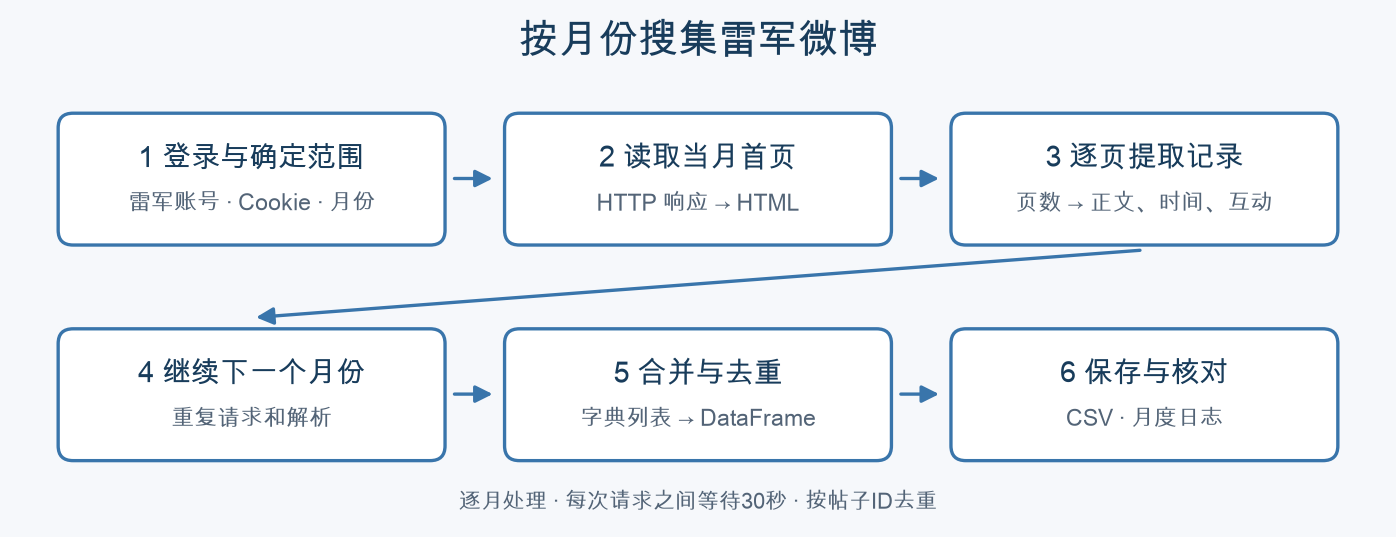

从登录与确定范围，到按月翻页、合并去重和保存。

```mermaid
flowchart LR
    A["登录微博<br/>获取 Cookie"] --> B["选择<br/>查询月份"]
    B --> C["请求该月<br/>第一页"]
    C --> D["解析微博<br/>读取总页数"]
    D --> E["逐页抓取<br/>该月微博"]
    E --> F{"还有<br/>下一个月吗？"}
    F -->|"有"| B
    F -->|"没有"| G["合并、去重<br/>保存 CSV"]
```

<a id="section-1"></a>
## 1 准备：账号、月份与 Cookie **[重点]**

打开 [雷军的微博](https://weibo.cn/1749127163/profile)，核对名称和数字 ID `1749127163`。
用户 ID 定位账号，页码定位一页，日期参数限定每次查询的时间范围。

按月查询便于分批处理和检查。整段历史查询可能只显示部分记录，按月也不能保证找回所有历史内容，
因此要核对页面时间、每月页数和实际抓到的数量。

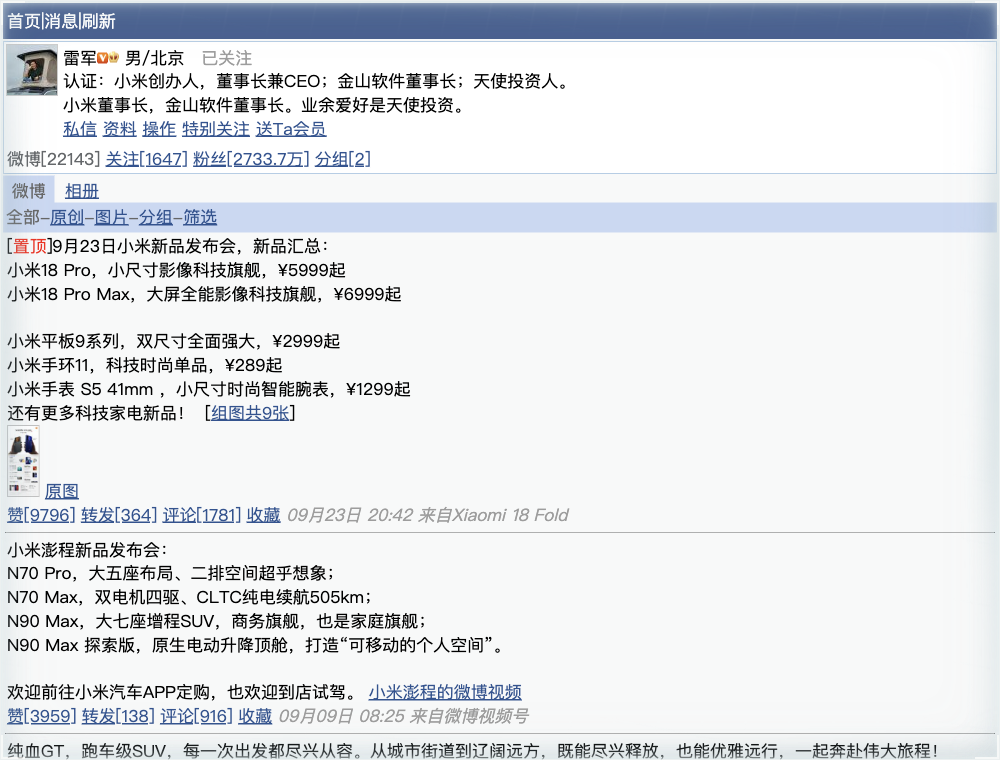

雷军公开用户页（2026年10月13日）。核对账号，再观察正文、时间与互动信息。

<a id="section-1-1"></a>
### 1.1 导入本课用到的库 **[拓展]**

`requests` 负责发送网页请求；`BeautifulSoup` 将 HTML 变成可查找的标签树；
`pandas` 组织月份和表格。`re` 提取互动数字，`time` 控制请求间隔，`Path` 定位保存目录。

In [ ]:
from pathlib import Path
import sys
import time
import re
import requests
from bs4 import BeautifulSoup
import pandas as pd
from IPython.display import display

# 选择安装了课程依赖的 Conda 或 venv 内核。
assert (Path(sys.prefix) / 'conda-meta').exists() or sys.prefix != sys.base_prefix, '请选择课程Python内核'
# 兼容从 tutorials 目录或项目根目录启动 Notebook。
TUTORIAL_DIR = Path('.') if Path('assets/weibo_crawler/test.html').is_file() else Path('tutorials')
OUT = TUTORIAL_DIR / 'output/crawler'
pd.set_option('display.max_colwidth', 75)

<a id="section-1-2"></a>
### 1.2 登录并取得自己的 Cookie **[重点]**

Cookie 是服务器识别登录会话的信息；本地 Python 不会自动继承浏览器的登录状态。

1. 在 Chrome／Edge 打开 `https://weibo.cn/`，登录自己的账号，再进入雷军的用户页。
2. 打开开发者工具：macOS 按 `⌘⌥I`，Windows／Linux 按 `F12` 或 `Ctrl+Shift+I`。
3. 选择 **Network（网络）**，刷新网页。点击 **Doc** 筛选，选择指向 `weibo.cn` 雷军用户页的 **document** 请求。
4. 打开 **Headers（标头）→ Request Headers（请求标头）**，找到 **Cookie**。
5. 在 Cookie 值上右键，选择 **Copy value（复制值）**；复制全部内容，不包含开头的 `Cookie:`。若菜单没有此项，选中完整值再复制。
6. 将值粘到下面 `COOKIE` 的引号之间。不要复制响应中的 `Set-Cookie`，也不要使用他人的会话。

Cookie 代表自己的登录身份。不要公开含真实 Cookie 的 Notebook、截图或代码，分享文件前清空该值。

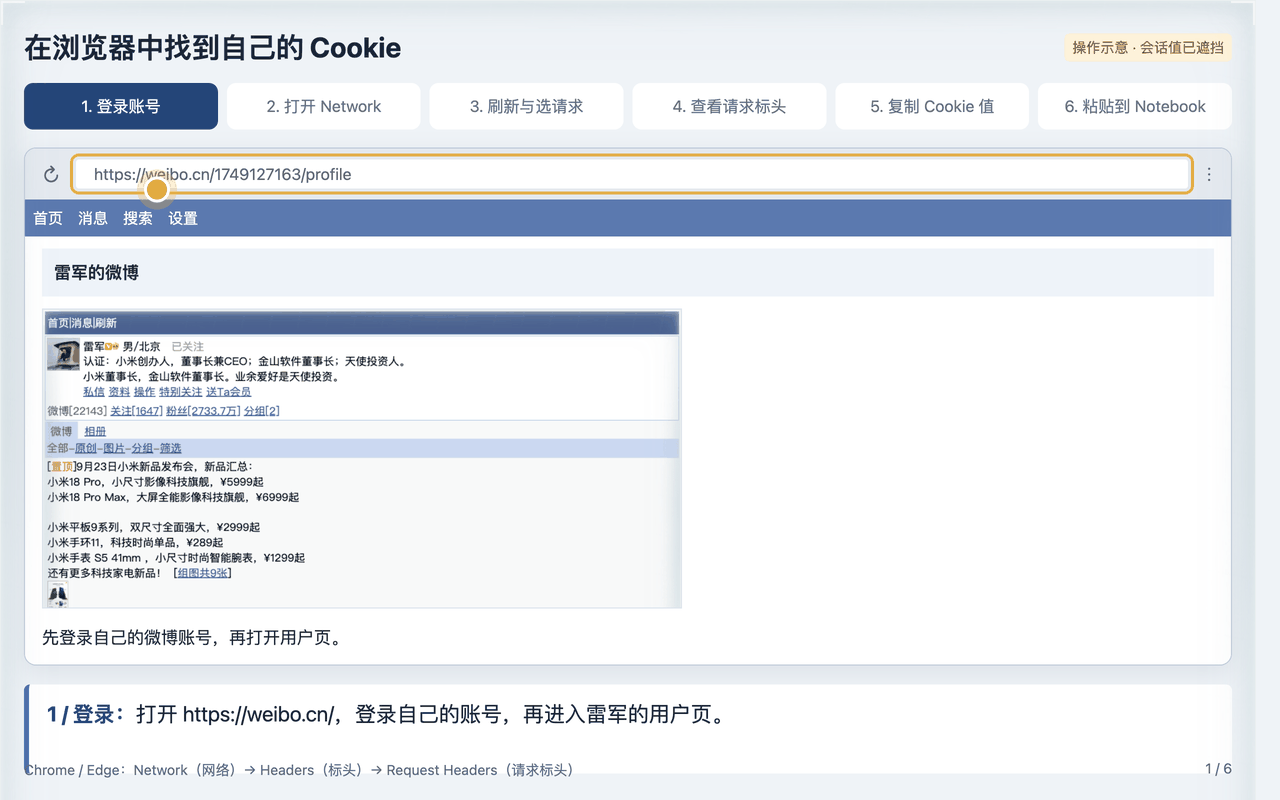

获取 Cookie 的六步操作示意。图中的会话值已遮挡，请在自己的浏览器中操作。

<details><summary>展开静态图：查看 Cookie 的复制位置</summary><p>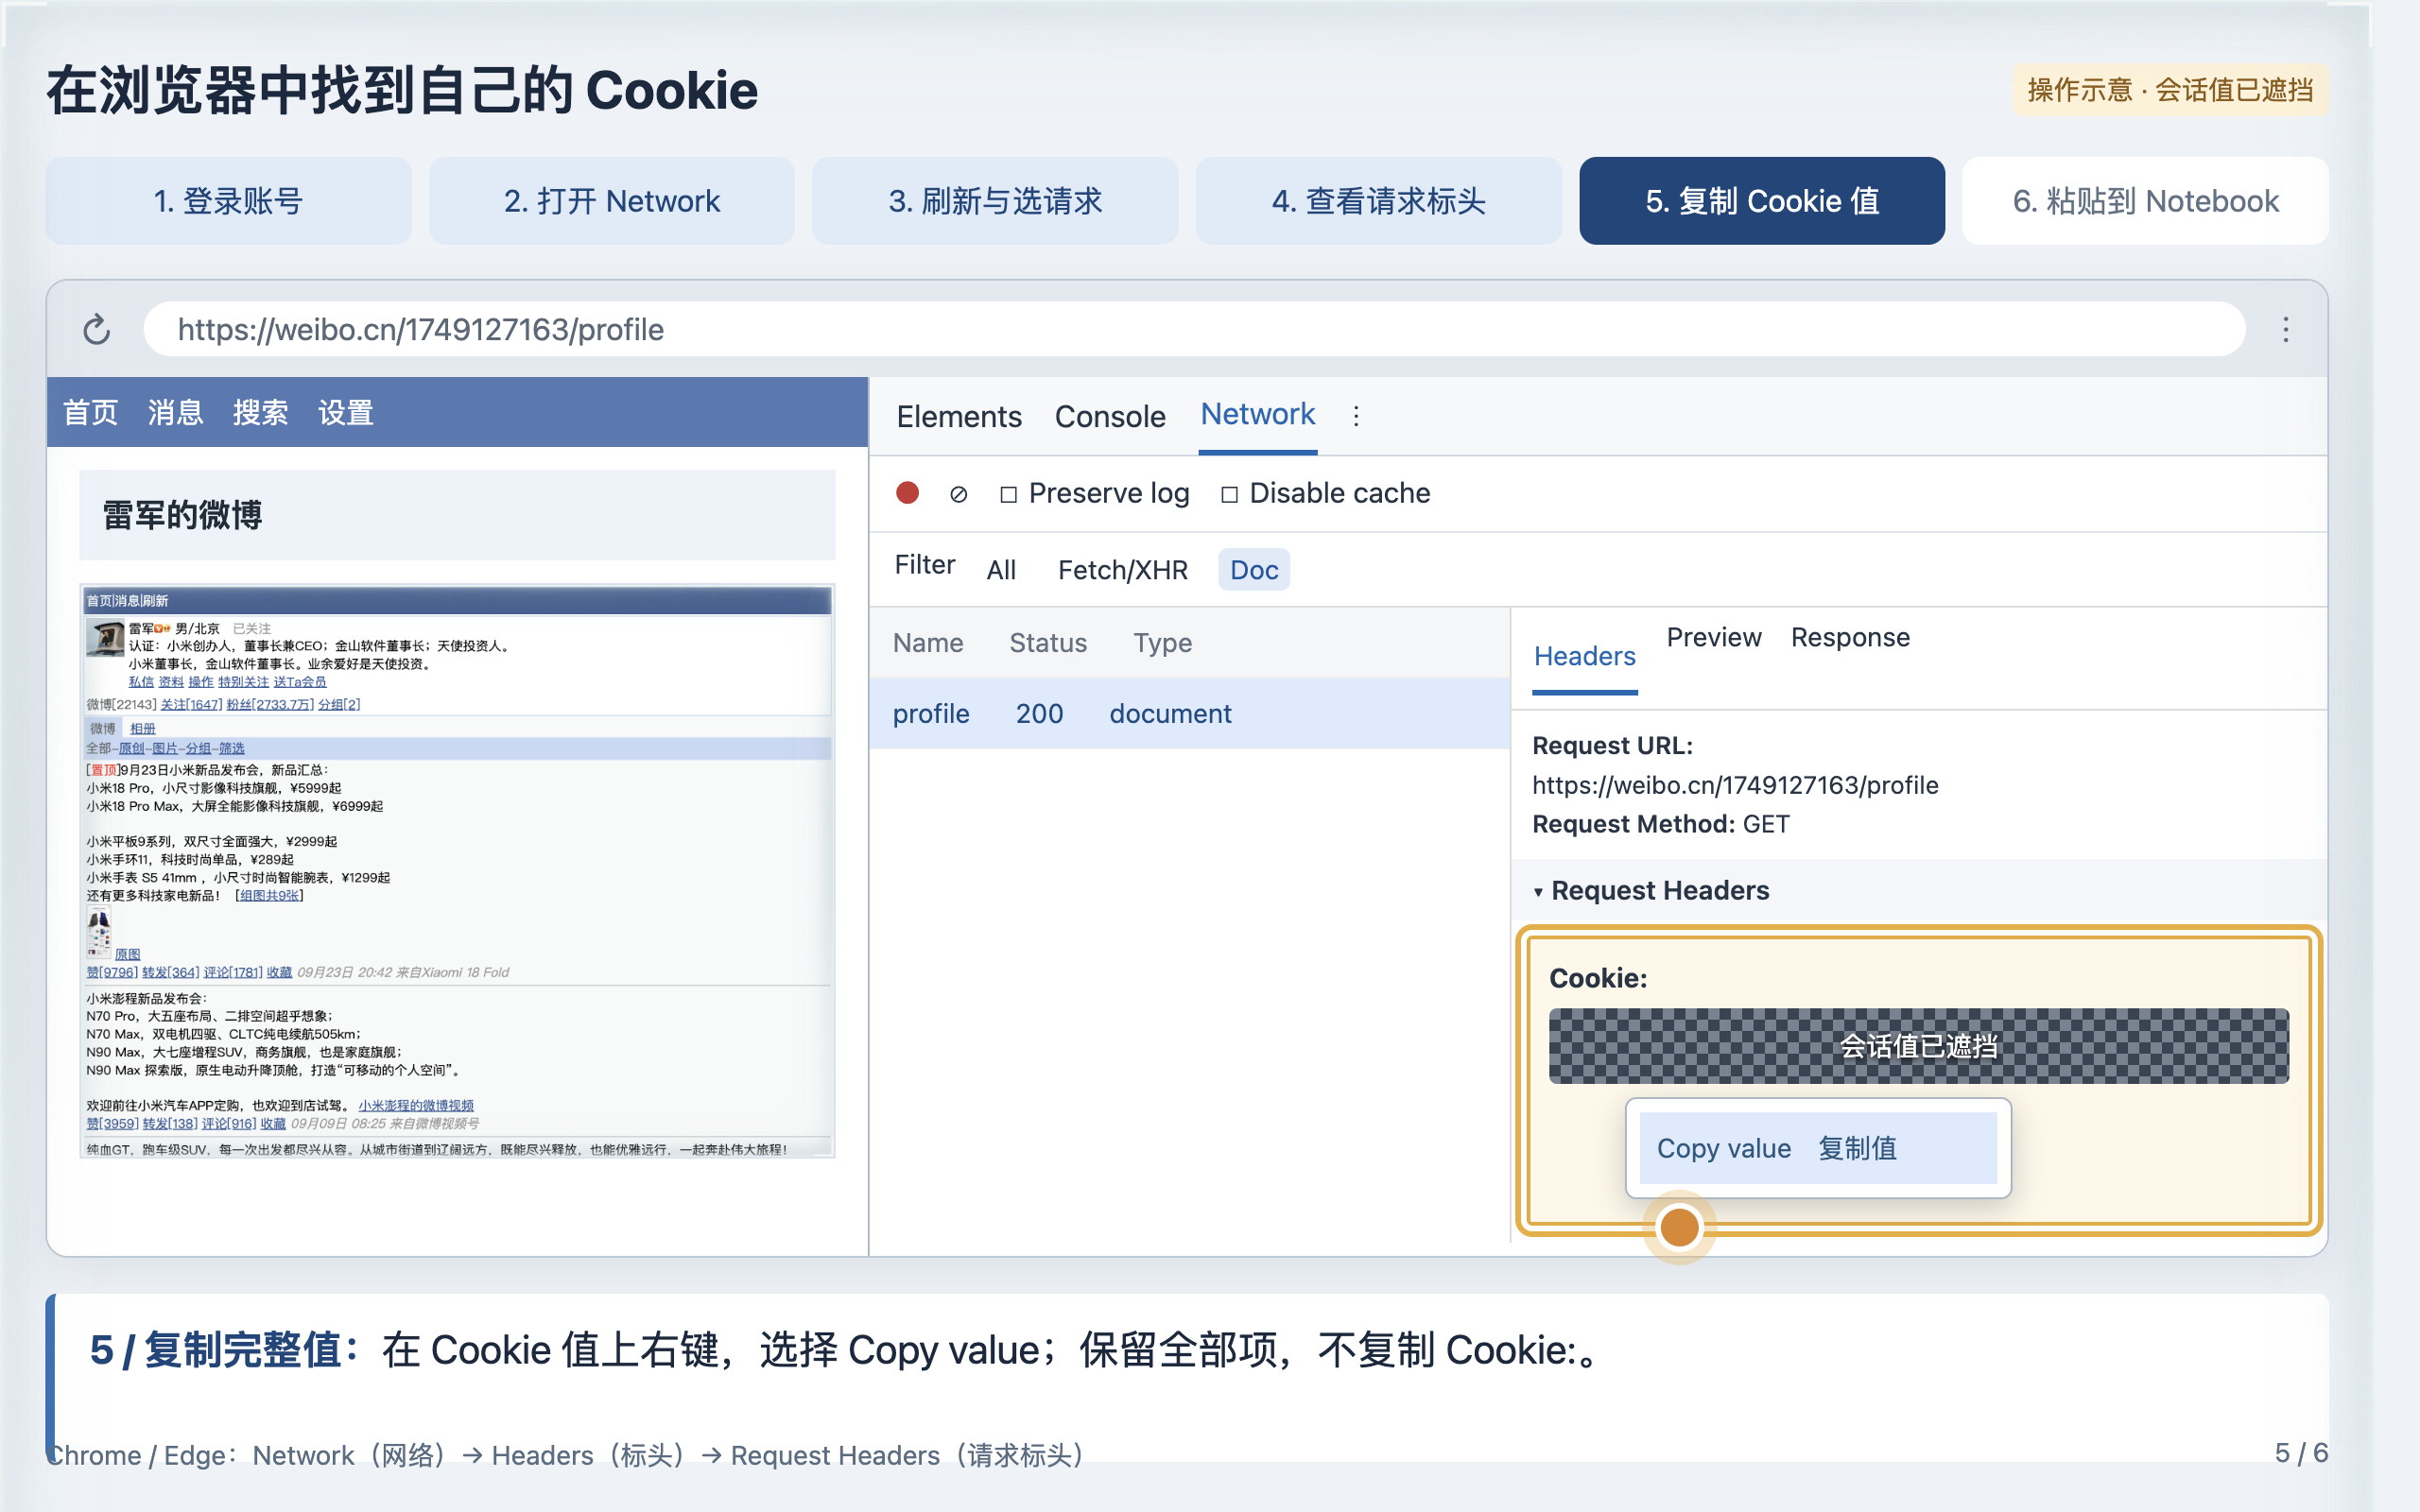</p><p>Request Headers 中的 Cookie → Copy value。</p></details>

In [ ]:
USER_ID = '1749127163'  # 雷军的数字用户 ID。
# 重点：填写自己的会话；不要打印、截图或提交含真实 Cookie 的 Notebook。
COOKIE = ''  # 在引号中粘贴自己登录 weibo.cn 后的 Cookie，不打印这个变量。

# 课堂先试跑2026年9月；结束值是下一月1日，不包含这个月。
START_MONTH = '2026-09-01'
END_MONTH = '2026-10-01'
# 搜集更长的历史时，可改为2009-01-01至2026-11-01，包含当前月份。
# 完整范围请求很多，可能需要数小时；先核对一个月，再扩展范围。
RUN_CRAWL = False  # 完成第一页检查后，改为 True 才启动月份循环。

<a id="section-2"></a>
## 2 第一次请求：从地址获得 HTML **[重点]**

<a id="section-2-1"></a>
### 2.1 用一个简单网页认识 HTTP 与 HTML **[重点]**

**HTTP** 是浏览器与服务器交换请求和响应的协议；**HTTPS** 在传输中使用加密连接。
请求中的 URL 指明资源地址，GET 表示读取，响应的状态码 `200` 表示 HTTP 请求成功。
**HTML** 描述页面结构，例如 `<h1>` 是标题，`<a href="...">` 是链接。
获取 HTML 与从 HTML 提取字段是两个步骤。

In [ ]:
# 只请求公开教学网页，不带 Cookie，也不访问微博。
DEMO_URL = 'https://wybert.github.io/social-media-analysis-tutorials/test.html'
response = requests.get(DEMO_URL, timeout=15)
response.raise_for_status()  # HTTP失败时停止。
response.encoding = 'utf-8'
print('HTTP状态：', response.status_code)
print('HTML开头：', response.text[:160])
# 解析后才能按标签取得标题。
print('标题：', BeautifulSoup(response.text, 'html.parser').h1.get_text())
response.close()

<a id="section-2-2"></a>
### 2.2 为一个月份组织请求参数 **[重点]**

在用户页点击“筛选”，可以设置起止日期。日期参数使用 `YYYYMMDD`，如 `20260901`。
`hasori=0` 表示全部，包含原创与转发；`hasori=1` 只筛选原创。
`haspic=0` 不按图片筛选，`advancedfilter=1` 启用筛选，`page` 控制页码。

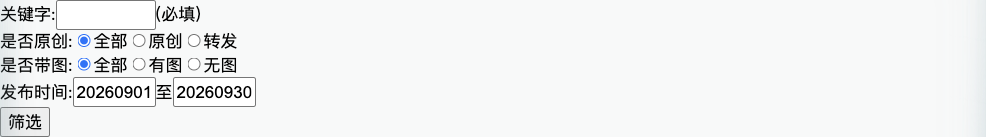

当前日期筛选页面：选择“全部”，将范围设为2026年9月1日至9月30日。

In [ ]:
# 月初日期列表；相邻两项构成一个月份的起止边界。
months = pd.date_range(START_MONTH, END_MONTH, freq='MS')
assert len(months) >= 2, '结束月份必须晚于开始月份'
preview_start, preview_end = months[0], months[1]
profile_url = f'https://weibo.cn/{USER_ID}/profile'
preview_params = {
    'hasori': 0, 'haspic': 0, 'advancedfilter': 1,
    'starttime': preview_start.strftime('%Y%m%d'),
    # 下月1日减去1天，得到本月最后一天。
    'endtime': (preview_end - pd.Timedelta(days=1)).strftime('%Y%m%d'),
    'page': 1,
}
# prepare只构造URL，不发送请求；观察日期和page参数。
print(requests.Request('GET', profile_url, params=preview_params).prepare().url)

<a id="section-2-3"></a>
### 2.3 练习：把请求地址改为第2页 **[练习]**

复制 `preview_params`，将 `page` 改成2，保存为 `second_page_params`。构造并显示地址，不发送请求。

<details><summary>展开 2.3 参考答案与代码</summary><pre><code class="language-python"># 重点：复制第一页参数，只改变 page；构造 URL 不发送请求。
# copy避免修改第一页的参数。
second_page_params = preview_params.copy()
second_page_params[&#x27;page&#x27;] = 2
print(requests.Request(&#x27;GET&#x27;, profile_url, params=second_page_params).prepare().url)</code></pre></details>

<a id="section-2-4"></a>
### 2.4 请求一个月份的一页

只需要一个下载函数。输入是月份起止边界与页码，返回的是 HTML 字符串。
`params` 将参数放入 URL，`headers` 携带自己的会话；两者用途不同。
登录跳转、网络或 HTTP 错误会中止，不自动重试。

In [ ]:
def get_html(start, end, page=1):
    """请求雷军在一个月份中的一页，返回HTML字符串。"""
    params = {
        'hasori': 0, 'haspic': 0, 'advancedfilter': 1,
        'starttime': start.strftime('%Y%m%d'),
        'endtime': (end - pd.Timedelta(days=1)).strftime('%Y%m%d'), 'page': page,
    }
    # Cookie仅发往固定的weibo.cn域名，不显示请求头。
    with requests.get(f'https://weibo.cn/{USER_ID}/profile', params=params,
                      headers={'User-Agent': 'Mozilla/5.0', 'Cookie': COOKIE},
                      timeout=15, allow_redirects=False) as result:
        if 300 <= result.status_code < 400:
            raise RuntimeError('发生登录跳转，请重新登录并更新Cookie')
        result.raise_for_status()
        result.encoding = 'utf-8'
        html = result.text
    # 正常用户页面有资料区域；登录页或限制页面不继续进入循环。
    if BeautifulSoup(html, 'html.parser').select_one('div.ut') is None:
        raise RuntimeError('未识别到用户页，请核查登录或访问限制')
    print(start.strftime('%Y-%m'), '第', page, '页：HTTP', result.status_code)
    return html

In [ ]:
preview_is_live = bool(COOKIE.strip())  # 标记第一页是否来自真实请求，示例不能混入抓取结果。
if preview_is_live:
    # 填写Cookie后，立即调用刚定义的函数；只请求当前范围的第一页。
    preview_html = get_html(preview_start, preview_end, page=1)
    print('真实HTML字符数：', len(preview_html))
else:
    # 无Cookie时只观察手工编写的标签结构；这些文字不是真实微博。
    preview_html = """<div class="ut">课堂结构示例，不是实际网页</div>
    <div class="c" id="M_CLASS_EXAMPLE"><span class="ctt">结构示例：学习网页解析。</span>
    <a href="/example">赞[12]</a><a href="/example">转发[0]</a><a href="/example">评论[3]</a>
    <span class="ct">2026-09-01 09:00 来自课堂结构示例</span></div>
    <div class="pa"><input name="mp" value="2"></div>"""
    print('Cookie未填写；下面展示手工HTML结构，不发生微博请求。')
print(preview_html[:200])

<a id="section-3"></a>
## 3 解析一条微博：标签变成字典 **[重点]**

用 Beautiful Soup 观察三个位置：`div.c[id]` 是有 ID 的帖子块，
`span.ctt` 是列表正文，`span.ct` 是时间与发布来源。`get_text()` 取文字，`.get('id')` 取属性。
在浏览器开发者工具的 Elements 中对照页面标签；页面结构变化时需要重新检查选择器。

In [ ]:
soup = BeautifulSoup(preview_html, 'html.parser')
# 只保留同时具有正文与时间的帖子块，不按固定位置切掉导航。
divs = [d for d in soup.select('div.c[id]') if d.select_one('span.ctt') and d.select_one('span.ct')]
print('本页帖子块数量：', len(divs))
if divs:
    print('正文标签：', divs[0].select_one('span.ctt'))
    print('时间标签：', divs[0].select_one('span.ct'))

下面的解析函数把一条帖子变成字典。正则 `赞\[(\d+)\]` 中，`\d+` 表示一个或多个数字，
`group(1)` 取得括号捕获的数字；未匹配到时保留 `None`，不当作0。
转发帖的列表正文可能是原文，雷军自己的“转发理由”另存一列。

In [ ]:
# 重点：一条标签块变成一个字典，一页的字典列表再变成表格。
def parse_one_weibo(div):
    """输入一个帖子标签块，返回一条记录字典。"""
    text = div.get_text(' ', strip=True)
    row = {
        'post_id': div.get('id'), 'user_id': USER_ID,
        'text': div.select_one('span.ctt').get_text(' ', strip=True),
        'time_raw': div.select_one('span.ct').get_text(' ', strip=True),
        'repost_reason': None,
    }
    if '转发理由:' in text:
        # 拆出转发理由，并去掉其后本帖的互动栏；需与页面人工对照。
        row['repost_reason'] = text.split('转发理由:', 1)[1].rsplit('赞[', 1)[0].strip()
    for field, label in [('thumb', '赞'), ('repost', '转发'), ('comment', '评论')]:
        # 反向遍历，先取转发帖自己的互动栏，避免误用原文互动数。
        row[field] = None
        for link in reversed(div.find_all('a', href=True)):
            match = re.fullmatch(label + r'\[(\d+)\]', link.get_text(strip=True))
            if match:
                row[field] = int(match.group(1))
                break
    return row

In [ ]:
if divs:
    # 定义后立即调用：输入标签块，输出字典，再显示为一行表格。
    first_record = parse_one_weibo(divs[0])
    print('返回类型：', type(first_record).__name__)
    display(pd.DataFrame([first_record]))
else:
    print('该月份没有可解析的记录，请回到浏览器检查。')

<a id="section-3-1"></a>
### 3.1 练习：提取一条帖子的时间 **[练习]**

在 `divs` 非空时，从第一条帖子的 `span.ct` 中取出文字，保存为 `time_student` 并显示。

<details><summary>展开 3.1 参考答案与代码</summary><pre><code class="language-python"># 重点：先选择 span.ct，再取文字；原始时间可能包含相对时间和发布来源。
if divs:
    time_student = divs[0].select_one(&#x27;span.ct&#x27;).get_text(&#x27; &#x27;, strip=True)
    print(time_student)</code></pre></details>

<a id="section-4"></a>
## 4 解析一整页：字典列表变成表格 **[重点]**

用 `for` 对本页每个帖子调用同一个解析函数，再交给 `DataFrame`。
一条字典是一行，字典中的键是列名。现在只整理了第一页，还没有开始月份循环。

In [ ]:
preview_rows = [parse_one_weibo(div) for div in divs]
preview_table = pd.DataFrame(preview_rows)
print('第一页记录数：', len(preview_table))
display(preview_table.head(3))

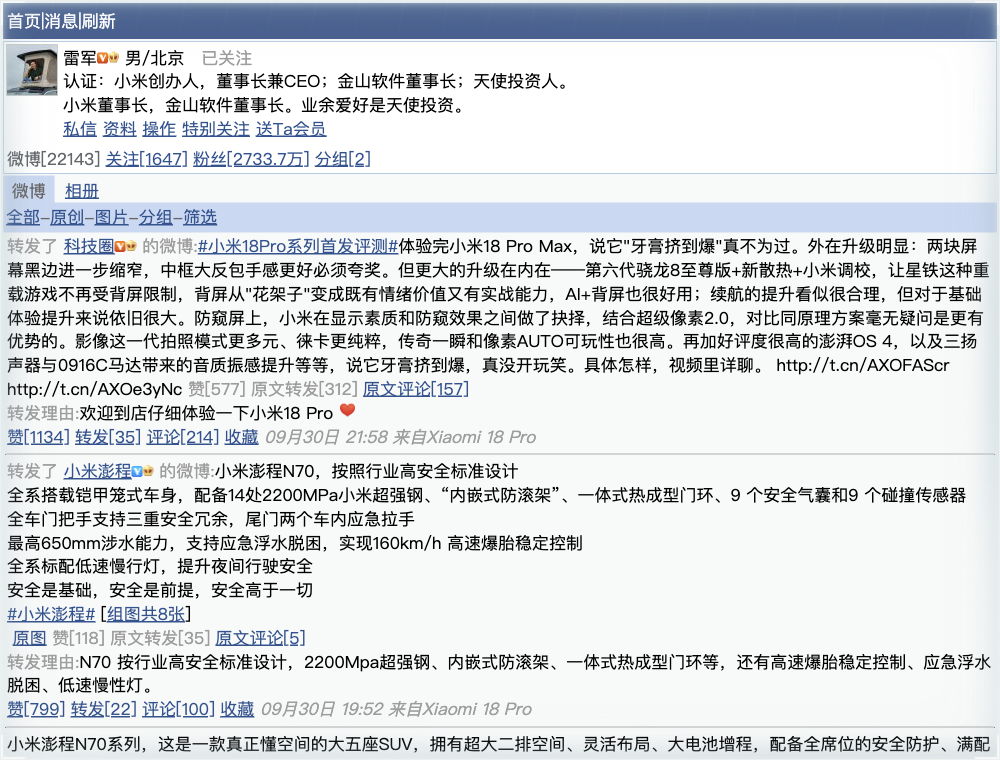

浏览器中2026年9月的筛选结果。对照日期、正文以及本帖的互动栏；截图时放大了文字并隐藏大图片。

<a id="section-4-1"></a>
### 4.1 这个月有多少页？ **[重点]**

分页区域的隐藏标签 `input[name="mp"]` 保存总页数，读取它的 `value` 属性。
一个正常用户页若没有分页标签，按一页处理，再通过帖子数量核对是否有结果。
页数描述当前查询结果，不证明已经获得完整历史。

In [ ]:
def get_page_num(soup):
    """输入HTML标签树，返回当前月份的页数。"""
    element = soup.select_one('input[name="mp"]')
    return int(element['value']) if element is not None else 1

In [ ]:
# 立即调用分页函数，观察整数输出。
page_count = get_page_num(soup)
print('本月页数：', page_count)
if COOKIE.strip() and not preview_table.empty:
    print('先核对本页时间范围：', preview_table['time_raw'].iloc[0], '→', preview_table['time_raw'].iloc[-1])

<a id="section-5"></a>
## 5 按月翻页：把同样的操作重复执行 **[重点]**

外层循环依次处理月份，内层循环处理这个月的全部页码。
每月先读第1页获取总页数，再抓剩余页；已经检查过的第一页直接复用，不重复请求。
每次新请求之前等待30秒。任何请求错误直接中止，不不断重试。

先将 `RUN_CRAWL` 改为 `True`，重新运行参数单元和下面的循环即可。
若扩大了日期范围，应重新运行“组织请求参数”和第一页检查单元。
单月页数过大时先缩小日期范围，不把超过120页的提示当作自动解决了完整性问题。

In [ ]:
all_records = []  # 汇集各月各页的帖子字典。
crawl_log = []    # 每页实际解析条数，用于核对覆盖范围。
if RUN_CRAWL and COOKIE.strip():
    # 重点：外层处理月份，内层处理页码；每个新请求之间等待30秒。
    for start, end in zip(months[:-1], months[1:]):
        if start == preview_start and end == preview_end and preview_is_live:
            first_html = preview_html  # 复用刚才的真实第一页。
        else:
            time.sleep(30)
            first_html = get_html(start, end, page=1)
        total_pages = get_page_num(BeautifulSoup(first_html, 'html.parser'))
        if total_pages > 120:
            raise RuntimeError('单月超过120页，请先缩小时间范围并核查网页结果')
        for page in range(1, total_pages + 1):
            if page == 1:
                html = first_html
            else:
                time.sleep(30)
                html = get_html(start, end, page)
            page_soup = BeautifulSoup(html, 'html.parser')
            blocks = [d for d in page_soup.select('div.c[id]') if d.select_one('span.ctt') and d.select_one('span.ct')]
            for block in blocks:
                row = parse_one_weibo(block)
                row['month_start'] = start.strftime('%Y-%m-%d')
                row['source_page'] = page
                all_records.append(row)
            crawl_log.append({'month_start': start.strftime('%Y-%m-%d'), 'page': page,
                              'total_pages': total_pages, 'parsed_rows': len(blocks)})
            print(start.strftime('%Y-%m'), page, '/', total_pages, '；本页', len(blocks), '条')
else:
    print('月份循环尚未启动；先填写Cookie并检查真实第一页，再设置RUN_CRAWL=True。')

<a id="section-6"></a>
## 6 合并、去重、保存与检查 **[重点]**

只按 `post_id` 去重，不按正文：不同帖子可能文字相同，置顶或时间边界又可能让同一帖子重复出现。
先检查每月页码和条数，再查看前三行，最后保存帖子表与抓取日志。
空月份只能说明本次查询未取得记录，不能断言雷军当月没有发帖。

In [ ]:
posts = pd.DataFrame(all_records)
if not posts.empty:
    before_count = len(posts)
    # 重点：按帖子 ID 去重；相同正文不一定是同一条帖子。
    posts = posts.drop_duplicates('post_id').reset_index(drop=True)
    print('去重前：', before_count, '；去重后：', len(posts))
    display(posts.head(3))
    # 每月统计解析数量，不将“代码跑完”直接等同于完整历史。
    display(pd.DataFrame(crawl_log).groupby('month_start').agg(
        requested_pages=('page', 'nunique'), parsed_rows=('parsed_rows', 'sum')))
    OUT.mkdir(parents=True, exist_ok=True)
    destination = OUT / f'leijun_{START_MONTH}_{END_MONTH}.csv'
    posts.to_csv(destination, index=False, encoding='utf-8-sig')
    pd.DataFrame(crawl_log).to_csv(destination.with_name(destination.stem + '_log.csv'), index=False, encoding='utf-8-sig')
    print('已保存：', destination)
else:
    print('尚无月份抓取结果，不保存手工结构示例。')

<a id="section-6-1"></a>
### 6.1 练习：按帖子ID去重 **[练习]**

用 `pd.concat([preview_table, preview_table], ignore_index=True)` 复制两遍表格，模拟重复记录，再用 `drop_duplicates` 按 `post_id` 去重，保存为 `unique_student` 并打印行数。不发送请求。

<details><summary>展开 6.1 参考答案与代码</summary><pre><code class="language-python"># 重点：按帖子 ID 去重；练习复制的行用于观察重复，不代表新增采集。
if not preview_table.empty:
    repeated = pd.concat([preview_table, preview_table], ignore_index=True)
    unique_student = repeated.drop_duplicates(&#x27;post_id&#x27;)
    print(&#x27;去重后：&#x27;, len(unique_student))</code></pre></details>

<a id="section-6-2"></a>
### 6.2 从一个月扩展到历史范围 **[拓展]**

确认一个月的日期筛选、分页和解析正确后，修改 `START_MONTH` 与 `END_MONTH`，重新运行日期准备与抓取流程。
例如 `2009-01-01` 到 `2026-11-01` 覆盖微博上线以来至本次课程当月；实际可见范围取决于账号和网页权限。
全范围请求很多，不要求在课内等到全部完成。

本课保留列表正文、原始时间文字、互动数和来源页码，不展开长微博全文或下载图片。
互动量是抓取时页面的观测值；“今天”“分钟前”等时间仍是字符串，不能直接当作绝对日期。
私有采集文件和填过 Cookie 的 Notebook 不提交公开仓库。
若抓取中断，可运行保存单元保留已经取得的记录；通过日志检查缺少哪些月份和页码，不能将部分结果标为全部。